In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path("../../arXiv-Project/data")          # dữ liệu thô, chỉ có trên máy
SUMMARY = Path("data/arxiv_2503_summary.csv")    # file tổng hợp, có trên GitHub

if DATA.exists():
    rows = []
    for d in sorted(DATA.glob("25*")):
        meta = json.loads((d / "metadata.json").read_text(encoding="utf-8"))
        refs_file = d / "references.json"
        refs = json.loads(refs_file.read_text(encoding="utf-8")) if refs_file.exists() else []
        for v in meta["versions"]:
            stamp = d / f"v{v.split('v')[-1]}" / ".complete"
            status, raw, ext = (stamp.read_text().strip().split("|") + ["", ""])[:3] if stamp.exists() else ("MISSING", "", "")
            rows.append({
                "arxiv_id": meta["arxiv_id"],
                "version": v,
                "n_versions": len(meta["versions"]),
                "n_authors": len(meta["authors"]),
                "n_refs": len(refs),
                "n_refs_arxiv": sum(r.get("ref_arxiv_id") is not None for r in refs),
                "status": status,
                "raw_bytes": int(raw.split(":")[1]) if raw else None,
                "extracted_bytes": int(ext.split(":")[1]) if ext else None,
            })
    df = pd.DataFrame(rows)
    SUMMARY.parent.mkdir(exist_ok=True)
    df.to_csv(SUMMARY, index=False)
else:
    df = pd.read_csv(SUMMARY)

papers = df.drop_duplicates("arxiv_id")
print(len(df), "versions |", len(papers), "papers")

8205 versions | 5000 papers


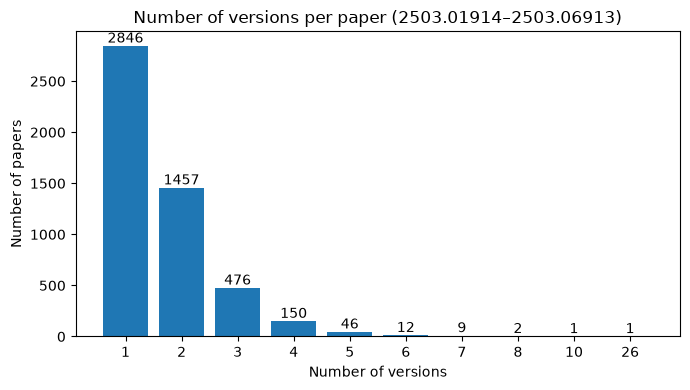

In [2]:
import matplotlib.pyplot as plt

counts = papers["n_versions"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(counts.index.astype(str), counts.values)
ax.set_title("Number of versions per paper (2503.01914–2503.06913)")
ax.set_xlabel("Number of versions")
ax.set_ylabel("Number of papers")
for x, y in zip(counts.index.astype(str), counts.values):
    ax.text(x, y, str(y), ha="center", va="bottom")   # in số trên mỗi cột
plt.tight_layout()
plt.show()

Most papers are never revised: 2,846 of the 5,000 papers (56.9%) have a single version, and the average is 1.64 versions per paper. Because the crawler downloads every version, this amounts to 8,205 source archives in total. The most revised paper, 2503.05136, has 26 versions.

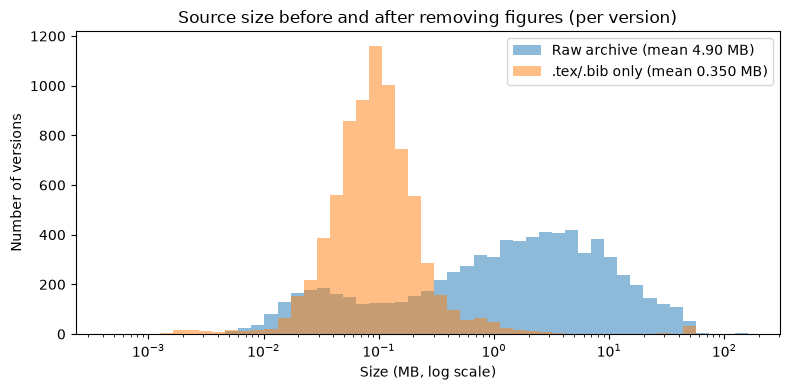

Total raw: 37192.9 MB | total kept: 2659.7 MB | reduction: 92.8%


In [3]:
import numpy as np

ok = df[df["status"] == "SUCCESS"].dropna(subset=["raw_bytes", "extracted_bytes"])
raw_mb = ok["raw_bytes"] / 1e6
ext_mb = ok["extracted_bytes"] / 1e6

bins = np.logspace(np.log10(min(raw_mb.min(), ext_mb[ext_mb > 0].min())),
                   np.log10(raw_mb.max()), 50)

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(raw_mb, bins=bins, alpha=0.5, label=f"Raw archive (mean {raw_mb.mean():.2f} MB)")
ax.hist(ext_mb[ext_mb > 0], bins=bins, alpha=0.5, label=f".tex/.bib only (mean {ext_mb.mean():.3f} MB)")
ax.set_xscale("log")
ax.set_title("Source size before and after removing figures (per version)")
ax.set_xlabel("Size (MB, log scale)")
ax.set_ylabel("Number of versions")
ax.legend()
plt.tight_layout()
plt.show()

print(f"Total raw: {raw_mb.sum():.1f} MB | total kept: {ext_mb.sum():.1f} MB "
      f"| reduction: {1 - ext_mb.sum() / raw_mb.sum():.1%}")

Keeping only `.tex` and `.bib` files shrinks the 7,591 successfully extracted versions from 37.2 GB to 2.7 GB, a 92.8% reduction; the median version drops from 1.56 MB to about 92 KB. Most of the archive size comes from figures (images) and compiled PDFs, which are removed. Note that `extracted_bytes` only counts files at the top level of each version folder (the crawler uses `iterdir`), so papers that keep their `.tex` files in subfolders are under-counted.

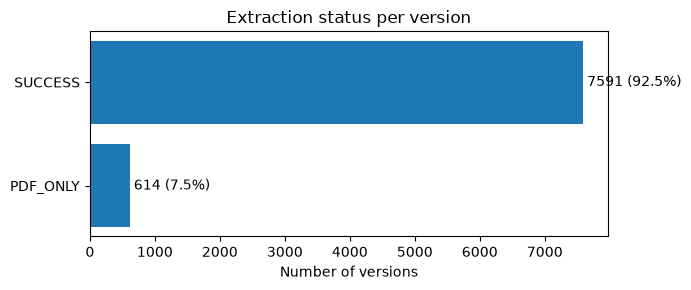

In [4]:
status = df["status"].value_counts()

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(status.index, status.values)
ax.set_title("Extraction status per version")
ax.set_xlabel("Number of versions")
for y, v in enumerate(status.values):
    ax.text(v, y, f" {v} ({v / status.sum():.1%})", va="center")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

Of the 8,205 versions, 7,591 (92.5%) were extracted successfully and 614 (7.5%) are `PDF_ONLY`. A `PDF_ONLY` version is a submission with no LaTeX source on arXiv; the crawler keeps an empty folder marked `PDF_ONLY` for it, so it is not counted as an error.

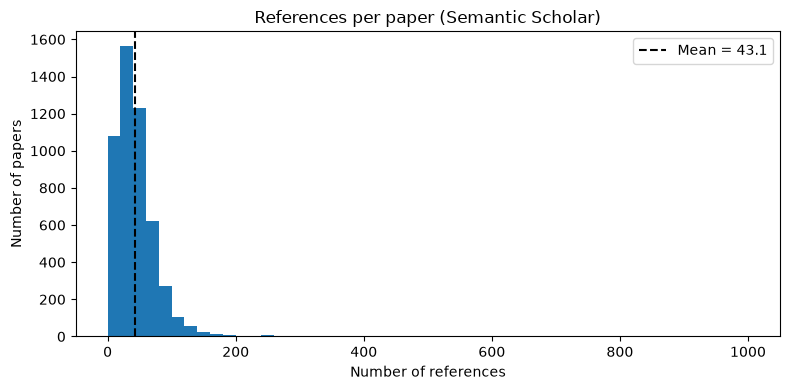

Papers with ≥1 reference:          94.6%
Papers with ≥1 arXiv reference:    87.4%
Mean arXiv references per paper:   20.0


In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(papers["n_refs"], bins=50)
ax.axvline(papers["n_refs"].mean(), linestyle="--", color="black",
           label=f"Mean = {papers['n_refs'].mean():.1f}")
ax.set_title("References per paper (Semantic Scholar)")
ax.set_xlabel("Number of references")
ax.set_ylabel("Number of papers")
ax.legend()
plt.tight_layout()
plt.show()

print(f"Papers with ≥1 reference:          {(papers['n_refs'] > 0).mean():.1%}")
print(f"Papers with ≥1 arXiv reference:    {(papers['n_refs_arxiv'] > 0).mean():.1%}")
print(f"Mean arXiv references per paper:   {papers['n_refs_arxiv'].mean():.1f}")

94.6% of papers have at least one reference on Semantic Scholar, with a mean of 43.1 and a median of 38 references per paper. 87.4% of papers cite at least one arXiv paper (20.0 arXiv references per paper on average); these are the rows kept in the references table. The 270 papers with zero references are likely not yet indexed by Semantic Scholar. The maximum is exactly 1,000 because that is the most Semantic Scholar returns in a single request, so that paper's list is truncated.